# DF-SA-MRFO-SAINT-DeepFM-GF — Pregnancy Outcome Prediction

## Install and import libraries

In [3]:


import os, json, time, math, random, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, roc_auc_score)
import shap

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.family": "DejaVu Sans",
                     "axes.titleweight": "bold", "axes.labelweight": "bold"})

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT_DIR = "results"
os.makedirs(OUT_DIR, exist_ok=True)
print("Device:", DEVICE, "| PyTorch", torch.__version__, "| SHAP", shap.__version__)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, name), bbox_inches="tight")
    plt.show()

Device: cuda | PyTorch 2.11.0+cu130 | SHAP 0.54.1


In [ ]:
# Explicitly install and import rtdl to ensure it is defined globally
import subprocess
import sys

try:
    import rtdl
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rtdl==0.0.13"])
    import rtdl

print("rtdl successfully imported. Version:", getattr(rtdl, "__version__", "0.0.13"))

## Experiment configuration

In [ ]:
TARGET = "Pregnancy_Outcome"

RUN_DFSAMRFO       = True
OPT_POP            = 10
OPT_ITERS          = 20        # iterations (T)
OPT_EPOCHS         = 50        # epochs per candidate
OPT_TRAIN_FRACTION = 1.0       # stratified fraction of the training subset
OPT_PATIENCE       = None         # early stopping

FINAL_EPOCHS       = 50
RES_ALPHA          = 0.10      # residual scaling coefficient
TAU                = 0.5       # decision threshold
EPS_CLIP           = 1e-7      # probability clipping

DEFAULT_HPARAMS = dict(lr=0.001, emb_dim=32, n_blocks=3, n_heads=4,
                      fm_hidden=128, dropout=0.20, batch_size=128, l2=1e-3)

# SHAP settings
SHAP_N_EXPLAIN    = 500        # test records
SHAP_N_BACKGROUND = 100        # background records

In [6]:
try:
    from google.colab import files
    uploaded = files.upload()
    DATA_PATH = list(uploaded.keys())[0]
except ImportError:
    DATA_PATH = "pregnancy_prediction_dataset.csv"

df = pd.read_csv(DATA_PATH) if DATA_PATH.lower().endswith(".csv") else pd.read_excel(DATA_PATH)
df.columns = [c.strip() for c in df.columns]
print("Shape:", df.shape)
id_like = [c for c in df.columns if c.lower() in ("id", "patient_id", "patientid", "record_id", "unnamed: 0")]
df = df.drop(columns=id_like)
print("Dropped identifier columns:", id_like)

# encode the target as 1 = Pregnant, 0 = Not Pregnant
if not pd.api.types.is_numeric_dtype(df[TARGET]):
    t = df[TARGET].astype(str).str.strip().str.lower()
    df[TARGET] = t.map(lambda v: 0 if ("not" in v or v in ("0", "no", "negative")) else 1).astype(int)
CLASS_NAMES = ["Not Pregnant", "Pregnant"]
print(df[TARGET].value_counts().rename(index={0: "Not Pregnant (0)", 1: "Pregnant (1)"}))

Saving Pregnancy_Prediction_Dataset.csv to Pregnancy_Prediction_Dataset.csv
Shape: (50000, 41)
Dropped identifier columns: []
Pregnancy_Outcome
Pregnant (1)        34404
Not Pregnant (0)    15596
Name: count, dtype: int64


## Stratified 70:15:15 partitioning

In [7]:
X_all = df.drop(columns=[TARGET])
y_all = df[TARGET].values.astype(int)

X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X_all, y_all, test_size=0.30, stratify=y_all, random_state=SEED)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

split_tbl = pd.DataFrame({
    "Subset": ["Training", "Validation", "Testing"],
    "Records": [len(y_train), len(y_val), len(y_test)],
    "Not Pregnant (0)": [(y_train == 0).sum(), (y_val == 0).sum(), (y_test == 0).sum()],
    "Pregnant (1)": [(y_train == 1).sum(), (y_val == 1).sum(), (y_test == 1).sum()]})

y_all = pd.concat([pd.Series(y_train), pd.Series(y_val), pd.Series(y_test)])

counts = y_all.value_counts().sort_index()
pct = (counts / counts.sum() * 100).round(1)

summary = pd.DataFrame({
    "Class": ["Not Pregnant (0)", "Pregnant (1)"],
    "Records": counts.values,
    "Percentage": pct.values
})

print(split_tbl.to_string(index=False))
print(summary.to_string(index=False))

    Subset  Records  Not Pregnant (0)  Pregnant (1)
  Training    35000             10917         24083
Validation     7500              2339          5161
   Testing     7500              2340          5160
           Class  Records  Percentage
Not Pregnant (0)    15596        31.2
    Pregnant (1)    34404        68.8


## Leakage-free preprocessing


In [8]:
print("Missing values in the complete dataset:", int(df.isna().sum().sum()))
print("Exact duplicate records:", int(df.duplicated().sum()))

MULTI_CAT_HINTS = ["exercise", "stress", "diet"]   # multi-category variables

num_cols, bin_cols, cat_cols = [], [], []
for c in X_train_raw.columns:
    s = X_train_raw[c]
    nun = s.dropna().nunique()
    if not pd.api.types.is_numeric_dtype(s):
        (bin_cols if nun <= 2 else cat_cols).append(c)
    elif any(h in c.lower() for h in MULTI_CAT_HINTS) and nun <= 10:
        cat_cols.append(c)
    elif nun <= 2:
        bin_cols.append(c)
    else:
        num_cols.append(c)
print(f"Continuous: {len(num_cols)} | Binary: {len(bin_cols)} | Multi-category: {len(cat_cols)}")
print("Multi-category columns:", cat_cols)

class TabularPreprocessor:
    def fit(self, X):
        self.medians = X[num_cols].median()
        self.bin_maps, self.bin_modes = {}, {}
        for c in bin_cols:
            vals = sorted(X[c].dropna().unique(), key=lambda v: str(v))
            pos = [v for v in vals if str(v).strip().lower() in ("1", "1.0", "yes", "true", "y", "present", "positive")]
            if pos:
                self.bin_maps[c] = {v: (1 if v in pos else 0) for v in vals}
            else:
                self.bin_maps[c] = {v: i for i, v in enumerate(vals)}
            self.bin_modes[c] = X[c].mode().iloc[0]
        self.cat_modes = {c: X[c].mode().iloc[0] for c in cat_cols}
        self.cat_vocab = {c: {v: i for i, v in enumerate(sorted(X[c].dropna().unique(), key=lambda v: str(v)))}
                          for c in cat_cols}
        Xn = X[num_cols].fillna(self.medians).astype(float)
        self.mu, self.sigma = Xn.mean(), Xn.std(ddof=0)
        return self

    def raw_imputed(self, X):
        out = pd.DataFrame(index=X.index)
        for c in num_cols: out[c] = X[c].fillna(self.medians[c]).astype(float)
        for c in bin_cols: out[c] = X[c].fillna(self.bin_modes[c]).map(self.bin_maps[c]).fillna(0).astype(float)
        for c in cat_cols:
            out[c] = X[c].fillna(self.cat_modes[c]).map(self.cat_vocab[c]).fillna(len(self.cat_vocab[c])).astype(float)
        return out

    def transform(self, X):
        R = self.raw_imputed(X)
        x_num = ((R[num_cols] - self.mu) / (self.sigma + 1e-8)).values if num_cols else np.zeros((len(X), 0))
        x_bin = R[bin_cols].values if bin_cols else np.zeros((len(X), 0))
        x_cont = np.hstack([x_num, x_bin]).astype(np.float32)          # numeric projection path
        x_cat = R[cat_cols].values.astype(np.int64) if cat_cols else np.zeros((len(X), 0), np.int64)  # lookup
        return x_cont, x_cat

prep = TabularPreprocessor().fit(X_train_raw)
Xc_tr, Xk_tr = prep.transform(X_train_raw)
Xc_va, Xk_va = prep.transform(X_val_raw)
Xc_te, Xk_te = prep.transform(X_test_raw)

CONT_FEATURES = num_cols + bin_cols
CAT_FEATURES = cat_cols
FEATURE_NAMES = CONT_FEATURES + CAT_FEATURES
CAT_CARDINALITIES = [len(prep.cat_vocab[c]) + 1 for c in cat_cols]   # +1 slot for unseen categories
print("Continuous tensor:", Xc_tr.shape, "| Categorical tensor:", Xk_tr.shape)
N_tr, K = len(y_train), 2
CLASS_W = torch.tensor([N_tr / (K * (y_train == c).sum()) for c in (0, 1)], dtype=torch.float32)
print("Class weights  w0 = %.4f, w1 = %.4f" % tuple(CLASS_W.tolist()))

Missing values in the complete dataset: 0
Exact duplicate records: 0
Continuous: 26 | Binary: 11 | Multi-category: 3
Multi-category columns: ['Exercise_Level', 'Stress_Level', 'Diet_Quality']
Continuous tensor: (35000, 37) | Categorical tensor: (35000, 3)
Class weights  w0 = 1.6030, w1 = 0.7267


## Model — SAINT branch, DeepFM branch, Adaptive Gated Feature Fusion, classification head

In [ ]:
class FeatureTokenizer(nn.Module):
    def __init__(self, n_cont, cat_cards, d):
        super().__init__()
        self.n_cont = n_cont
        self.w = nn.Parameter(torch.randn(n_cont, d) * 0.02)
        self.b = nn.Parameter(torch.zeros(n_cont, d))
        self.cat_emb = nn.ModuleList([nn.Embedding(k, d) for k in cat_cards])
    def forward(self, x_cont, x_cat):
        tok = [x_cont.unsqueeze(-1) * self.w + self.b] if self.n_cont else []
        if len(self.cat_emb):
            tok.append(torch.stack([emb(x_cat[:, j]) for j, emb in enumerate(self.cat_emb)], dim=1))
        return torch.cat(tok, dim=1)

class SAINTBlock(nn.Module):
    def __init__(self, p, d, heads, dropout):
        super().__init__()
        self.feat_attn = nn.MultiheadAttention(d, heads, dropout=dropout, batch_first=True)
        self.row_proj_in = nn.Linear(p * d, d)
        self.row_attn = nn.MultiheadAttention(d, heads, dropout=dropout, batch_first=True)
        self.row_proj_out = nn.Linear(d, p * d)
        self.ln1 = nn.LayerNorm(d); self.ln2 = nn.LayerNorm(d)
        self.ffn = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Dropout(dropout), nn.Linear(4 * d, d))
        self.drop = nn.Dropout(dropout)
    def forward(self, H):
        B, p, d = H.shape
        Hf, _ = self.feat_attn(H, H, H)
        r = self.row_proj_in(Hf.reshape(B, p * d)).unsqueeze(0)
        Zr, _ = self.row_attn(r, r, r)
        Hr = Hf + self.row_proj_out(Zr.squeeze(0)).reshape(B, p, d)
        U = self.ln1(H + self.drop(Hr))
        return self.ln2(U + self.drop(self.ffn(U)))

class SAINTBranch(nn.Module):
    def __init__(self, n_cont, cat_cards, d, n_blocks, heads, dropout):
        super().__init__()
        p = n_cont + len(cat_cards)
        self.tok = FeatureTokenizer(n_cont, cat_cards, d)
        self.col_emb = nn.Parameter(torch.randn(1, p, d) * 0.02)
        self.blocks = nn.ModuleList([SAINTBlock(p, d, heads, dropout) for _ in range(n_blocks)])
        self.out_dim = d
    def forward(self, x_cont, x_cat):
        H = self.tok(x_cont, x_cat) + self.col_emb
        for blk in self.blocks: H = blk(H)
        return H.mean(dim=1)

class DeepFMBranch(nn.Module):
    def __init__(self, n_cont, cat_cards, d, hidden, dropout):
        super().__init__()
        p = n_cont + len(cat_cards)
        self.tok = FeatureTokenizer(n_cont, cat_cards, d)
        self.lin_cont = nn.Linear(n_cont, 1) if n_cont else None
        self.lin_cat = nn.ModuleList([nn.Embedding(k, 1) for k in cat_cards])
        self.mlp = nn.Sequential(nn.Linear(p * d, hidden), nn.BatchNorm1d(hidden), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(hidden, hidden // 2), nn.BatchNorm1d(hidden // 2), nn.ReLU(), nn.Dropout(dropout))
        self.out_dim = 2 + hidden // 2
    def forward(self, x_cont, x_cat):
        B = x_cont.shape[0]
        y1 = self.lin_cont(x_cont) if self.lin_cont is not None else torch.zeros(B, 1, device=x_cont.device)
        for j, emb in enumerate(self.lin_cat): y1 = y1 + emb(x_cat[:, j])
        V = self.tok(x_cont, x_cat)
        y2 = 0.5 * (V.sum(1).pow(2) - V.pow(2).sum(1)).sum(1, keepdim=True)
        h_deep = self.mlp(V.reshape(B, -1))
        return torch.cat([y1, y2, h_deep], dim=1)

class AdaptiveGatedFusion(nn.Module):
    def __init__(self, d_s, d_d, d_f, alpha=RES_ALPHA):
        super().__init__()
        self.Ws, self.Wd = nn.Linear(d_s, d_f), nn.Linear(d_d, d_f)
        self.Wg, self.Wr = nn.Linear(2 * d_f, d_f), nn.Linear(2 * d_f, d_f)
        self.alpha = alpha
    def forward(self, r_saint, r_deepfm, return_gate=False):
        zs, zd = self.Ws(r_saint), self.Wd(r_deepfm)
        z = torch.cat([zs, zd], dim=1)
        g = torch.sigmoid(self.Wg(z))
        r = g * zs + (1 - g) * zd + self.alpha * self.Wr(z)
        return (r, g) if return_gate else r

class SAINTDeepFMGF(nn.Module):
    def __init__(self, n_cont, cat_cards, hp):
        super().__init__()
        d = hp["emb_dim"]
        self.saint = SAINTBranch(n_cont, cat_cards, d, hp["n_blocks"], hp["n_heads"], hp["dropout"])
        self.deepfm = DeepFMBranch(n_cont, cat_cards, d, hp["fm_hidden"], hp["dropout"])
        self.fusion = AdaptiveGatedFusion(self.saint.out_dim, self.deepfm.out_dim, d)
        self.head = nn.Sequential(nn.Linear(d, d), nn.GELU(), nn.Dropout(hp["dropout"]), nn.Linear(d, 1))
    def forward(self, x_cont, x_cat):
        return self.head(self.fusion(self.saint(x_cont, x_cat), self.deepfm(x_cont, x_cat))).squeeze(1)  # logit o_i

## Training utilities — class-weighted BCE + L2, fixed deterministic evaluation batches

In [ ]:
def make_loader(xc, xk, y, batch_size, shuffle):
    ds = TensorDataset(torch.from_numpy(xc), torch.from_numpy(xk), torch.from_numpy(y.astype(np.float32)))
    g = torch.Generator(); g.manual_seed(SEED)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, generator=g, drop_last=False)

def weighted_bce(logits, y):
    p = torch.sigmoid(logits.float()).clamp(EPS_CLIP, 1 - EPS_CLIP)
    w = torch.where(y > 0.5, CLASS_W[1], CLASS_W[0]).to(logits.device)
    return -(w * (y * torch.log(p) + (1 - y) * torch.log(1 - p))).mean()

def l2_penalty(model, lam):
    return lam * sum((W ** 2).sum() for n, W in model.named_parameters() if W.dim() > 1 and "emb" not in n)

@torch.no_grad()
def predict_proba(model, xc, xk, batch_size):
    model.eval(); out = []
    for i in range(0, len(xc), batch_size):
        c = torch.from_numpy(xc[i:i + batch_size]).to(DEVICE)
        k = torch.from_numpy(xk[i:i + batch_size]).to(DEVICE)
        out.append(torch.sigmoid(model(c, k)).float().cpu().numpy())
    return np.concatenate(out)

@torch.no_grad()
def evaluate(model, loader):
    model.eval(); tot_loss, n, correct = 0.0, 0, 0
    for c, k, y in loader:
        c, k, y = c.to(DEVICE), k.to(DEVICE), y.to(DEVICE)
        logits = model(c, k)
        tot_loss += weighted_bce(logits, y).item() * len(y); n += len(y)
        correct += ((torch.sigmoid(logits) >= TAU).float() == y).sum().item()
    return tot_loss / n, correct / n

def train_model(hp, data, epochs, patience=None, verbose=False, seed=SEED):
    set_seed(seed)
    (xc_tr, xk_tr, ytr), (xc_va, xk_va, yva) = data
    tr_loader = make_loader(xc_tr, xk_tr, ytr, hp["batch_size"], shuffle=True)
    va_loader = make_loader(xc_va, xk_va, yva, hp["batch_size"], shuffle=False)
    model = SAINTDeepFMGF(xc_tr.shape[1], CAT_CARDINALITIES, hp).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=hp["lr"])
    use_amp = DEVICE.type == "cuda"
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_loss, best_state, wait = float("inf"), None, 0
    for ep in range(1, epochs + 1):
        model.train(); tl, tc, tn = 0.0, 0, 0
        for c, k, y in tr_loader:
            c, k, y = c.to(DEVICE), k.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                logits = model(c, k)
            loss = weighted_bce(logits, y) + l2_penalty(model, hp["l2"])
            scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            tl += weighted_bce(logits.detach(), y).item() * len(y); tn += len(y)
            tc += ((torch.sigmoid(logits.detach()) >= TAU).float() == y).sum().item()
        vl, va = evaluate(model, va_loader)
        hist["train_loss"].append(tl / tn); hist["train_acc"].append(tc / tn)
        hist["val_loss"].append(vl); hist["val_acc"].append(va)
        if verbose:
            print(f"Epoch {ep:02d}/{epochs} | train loss {tl/tn:.4f} acc {tc/tn:.4f} | val loss {vl:.4f} acc {va:.4f}")
        if vl < best_loss - 1e-6:
            best_loss, best_state, wait = vl, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if patience and wait >= patience: break
    model.load_state_dict(best_state)
    return model, hist, best_loss

## Bio-inspired DF-SA-MRFO hyperparameter optimization


In [ ]:
SEARCH_SPACE = [  # name, low, high, type
    ("lr",         1e-4, 2e-3, "log"),
    ("emb_dim",    16,   128,  "int"),
    ("n_blocks",   2,    6,    "int"),
    ("n_heads",    2,    8,    "int"),
    ("fm_hidden",  64,   512,  "int"),
    ("dropout",    0.10, 0.50, "float"),
    ("batch_size", 64,   256,  "int"),
    ("l2",         1e-6, 1e-2, "log"),
]
DIM = len(SEARCH_SPACE)

def decode(pos):
    hp = {}
    for v, (name, lo, hi, kind) in zip(np.clip(pos, 0, 1), SEARCH_SPACE):
        if kind == "log":   hp[name] = float(10 ** (np.log10(lo) + v * (np.log10(hi) - np.log10(lo))))
        elif kind == "int": hp[name] = int(round(lo + v * (hi - lo)))
        else:               hp[name] = float(lo + v * (hi - lo))
    hp["n_heads"] = int(2 ** round(np.log2(hp["n_heads"])))
    hp["emb_dim"] = int(max(16, 8 * round(hp["emb_dim"] / 8)))
    hp["fm_hidden"] = int(32 * round(hp["fm_hidden"] / 32))
    hp["batch_size"] = int(32 * round(hp["batch_size"] / 32))
    hp["lr"] = float(f"{hp['lr']:.5f}"); hp["dropout"] = round(hp["dropout"], 2); hp["l2"] = float(f"{hp['l2']:.1e}")
    return hp

def encode(hp):
    pos = []
    for name, lo, hi, kind in SEARCH_SPACE:
        v = hp[name]
        pos.append((np.log10(v) - np.log10(lo)) / (np.log10(hi) - np.log10(lo)) if kind == "log" else (v - lo) / (hi - lo))
    return np.clip(np.array(pos), 0, 1)

if OPT_TRAIN_FRACTION < 1.0:
    idx_sub, _ = train_test_split(np.arange(len(y_train)), train_size=OPT_TRAIN_FRACTION,
                                  stratify=y_train, random_state=SEED)
else:
    idx_sub = np.arange(len(y_train))
OPT_DATA = ((Xc_tr[idx_sub], Xk_tr[idx_sub], y_train[idx_sub]), (Xc_va, Xk_va, y_val))

_fitness_cache, OPT_LOG = {}, []
def fitness(pos):
    """F(θ) = validation loss of the configuration; identical decoded configurations are cached."""
    hp = decode(pos); key = json.dumps(hp, sort_keys=True)
    if key not in _fitness_cache:
        t0 = time.time()
        _, _, vloss = train_model(hp, OPT_DATA, OPT_EPOCHS, patience=OPT_PATIENCE)
        _fitness_cache[key] = vloss
        OPT_LOG.append({**hp, "val_loss": vloss, "seconds": round(time.time() - t0, 1)})
        pd.DataFrame(OPT_LOG).to_csv(os.path.join(OUT_DIR, "dfsamrfo_evaluations.csv"), index=False)
    return _fitness_cache[key]

def df_sa_mrfo(Q=OPT_POP, T=OPT_ITERS, omega_min=0.5, omega_max=2.0, rho=0.20, alpha0=1.0, beta0=0.50,
               xi0=0.10, tau_s=1e-4, stall_iters=5, disp_scale=0.05, eps=1e-12, seed=SEED):
    rng = np.random.default_rng(seed)
    theta = rng.random((Q, DIM))
    fit = np.array([fitness(th) for th in theta])
    b = int(np.argmin(fit)); best_pos, best_fit = theta[b].copy(), fit[b]
    D0 = np.mean(np.linalg.norm(theta - theta.mean(0), axis=1))
    beta, stall = beta0, 0
    history = [{"iter": 0, "best_val_loss": float(best_fit), "diversity": 1.0, "success_rate": None}]
    for t in range(1, T + 1):
        prev_best = best_fit
        Dt = np.mean(np.linalg.norm(theta - theta.mean(0), axis=1))
        delta = Dt / (D0 + eps)
        omega = float(np.clip(1 - delta, omega_min, omega_max))
        alpha = alpha0 * (1 - t / T) + omega * t / T
        p_explore = alpha / (alpha + beta)
        s = np.zeros(Q); disp = np.zeros_like(theta)
        for q in range(Q):
            if rng.random() < p_explore:
                r = rng.choice([i for i in range(Q) if i != q])
                trial = theta[q] + alpha * rng.random(DIM) * (theta[r] - theta[q])
            else:
                trial = theta[q] + beta * rng.random(DIM) * (best_pos - theta[q])
            trial = np.clip(trial, 0, 1)
            f_trial = fitness(trial)
            if f_trial < fit[q]:
                s[q] = 1; disp[q] = trial - theta[q]; theta[q], fit[q] = trial, f_trial
        SR = s.mean()
        gamma = beta * SR
        beta = (1 - rho) * beta + rho * SR
        mean_dir = disp.sum(0) / (s.sum() + eps) if s.sum() > 0 else np.zeros(DIM)
        for q in range(Q):
            new = theta[q] + gamma * mean_dir
            new = new + omega * rng.normal(0, disp_scale, DIM)
            new = np.clip(new, 0, 1)
            f_new = fitness(new)
            if f_new < fit[q]:
                theta[q], fit[q] = new, f_new
            if f_new < best_fit: best_pos, best_fit = new.copy(), f_new
        b = int(np.argmin(fit))
        if fit[b] < best_fit: best_pos, best_fit = theta[b].copy(), fit[b]
        stall = stall + 1 if abs(prev_best - best_fit) < tau_s else 0
        if stall >= stall_iters:
            xi = xi0 * (1 - t / T)
            worst = np.argsort(fit)[-(Q // 2):]
            for q in worst:
                theta[q] = np.clip(best_pos + xi * rng.uniform(-1, 1, DIM), 0, 1)
                fit[q] = fitness(theta[q])
                if fit[q] < best_fit: best_pos, best_fit = theta[q].copy(), fit[q]
            stall = 0
        history.append({"iter": t, "best_val_loss": float(best_fit), "diversity": float(delta), "success_rate": float(SR)})
    return decode(best_pos), best_fit, history

if RUN_DFSAMRFO:
    t0 = time.time()
    BEST_HP, BEST_FIT, CONV_HISTORY = df_sa_mrfo()
    print(f"DF-SA-MRFO finished in {(time.time() - t0) / 60:.1f} min — {len(_fitness_cache)} unique configurations trained")
else:
    BEST_HP, BEST_FIT, CONV_HISTORY = dict(DEFAULT_HPARAMS), None, []
pd.DataFrame(CONV_HISTORY).to_csv(os.path.join(OUT_DIR, "dfsamrfo_convergence.csv"), index=False)

hp_tbl = pd.DataFrame({"Hyperparameter": ["Learning Rate", "Embedding Dimension", "Number of SAINT Blocks",
                                          "Number of Attention Heads", "DeepFM Hidden Units", "Dropout Rate",
                                          "Batch Size", "L2 Regularization Coefficient"],
                       "Optimized Value": [BEST_HP[k] for k in ["lr", "emb_dim", "n_blocks", "n_heads",
                                                                "fm_hidden", "dropout", "batch_size", "l2"]]})
print(hp_tbl.to_string(index=False))

DF-SA-MRFO finished in 302.8 min — 419 unique configurations trained
               Hyperparameter  Optimized Value
                Learning Rate           0.0008
          Embedding Dimension          64.0000
       Number of SAINT Blocks           4.0000
    Number of Attention Heads           4.0000
          DeepFM Hidden Units         256.0000
                 Dropout Rate           0.3000
                   Batch Size         128.0000
L2 Regularization Coefficient           0.0001


## Final training

In [ ]:
FULL_DATA = ((Xc_tr, Xk_tr, y_train), (Xc_va, Xk_va, y_val))
t0 = time.time()
final_model, HIST, best_val = train_model(BEST_HP, FULL_DATA, FINAL_EPOCHS, patience=None, verbose=True)
torch.save({"state_dict": final_model.state_dict(), "hparams": BEST_HP}, os.path.join(OUT_DIR, "df_sa_mrfo_saint_deepfm_gf.pt"))

Epoch 01/50 | train loss 0.2683 acc 0.8781 | val loss 0.1892 acc 0.9199
Epoch 02/50 | train loss 0.2378 acc 0.8899 | val loss 0.1677 acc 0.9273
Epoch 03/50 | train loss 0.2128 acc 0.9013 | val loss 0.1505 acc 0.9337
Epoch 04/50 | train loss 0.1911 acc 0.9079 | val loss 0.1290 acc 0.9436
Epoch 05/50 | train loss 0.1682 acc 0.9156 | val loss 0.1137 acc 0.9468
Epoch 06/50 | train loss 0.1503 acc 0.9228 | val loss 0.1016 acc 0.9489
Epoch 07/50 | train loss 0.1372 acc 0.9296 | val loss 0.0937 acc 0.9566
Epoch 08/50 | train loss 0.1220 acc 0.9365 | val loss 0.0829 acc 0.9623
Epoch 09/50 | train loss 0.1078 acc 0.9424 | val loss 0.0727 acc 0.9639
Epoch 10/50 | train loss 0.0985 acc 0.9472 | val loss 0.0679 acc 0.9629
Epoch 11/50 | train loss 0.0874 acc 0.9523 | val loss 0.0608 acc 0.9664
Epoch 12/50 | train loss 0.0789 acc 0.9553 | val loss 0.0574 acc 0.9735
Epoch 13/50 | train loss 0.0725 acc 0.9606 | val loss 0.0491 acc 0.9717
Epoch 14/50 | train loss 0.0627 acc 0.9617 | val loss 0.0459 acc

## Baseline comparison analysis


In [ ]:
import subprocess, sys
def _ensure(pip_name, module):
    try: __import__(module)
    except ImportError: subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])
_ensure("xgboost==2.0.3", "xgboost"); _ensure("lightgbm", "lightgbm"); _ensure("catboost", "catboost")
_ensure("pytorch-tabnet==4.1.0", "pytorch_tabnet"); _ensure("rtdl==0.0.13", "rtdl"); _ensure("optuna", "optuna"); _ensure("scipy", "scipy")   # paper: rtdl 0.0.13

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import lightgbm as lgb, optuna
from scipy.stats import chi2
optuna.logging.set_verbosity(optuna.logging.WARNING)

N_BOOT_BASE, CI_LVL = 2000, 0.95
n_cont, n_cat = Xc_tr.shape[1], Xk_tr.shape[1]


# (a) LR / SVM / MLP
ohe = OneHotEncoder(handle_unknown="ignore").fit(Xk_tr) if n_cat else None
def lin_feats(xc, xk):
    return np.hstack([xc] + ([ohe.transform(xk).toarray()] if n_cat else [])).astype(np.float32)
# (b) RF / XGBoost / LightGBM
def tree_feats(X_raw):
    return prep.raw_imputed(X_raw)[FEATURE_NAMES].values.astype(np.float32)
# (c) CatBoost
def cat_df(X_raw):
    d = pd.DataFrame(tree_feats(X_raw), columns=FEATURE_NAMES); d[cat_cols] = d[cat_cols].astype(int); return d
# (d) TabNet
def tabnet_feats(xc, xk): return np.hstack([xc, xk.astype(np.float32)]).astype(np.float32)

# metrics and stratified bootstrap CI
def _metrics_from_counts(tp, fn, fp, tn):
    prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
    return {"Accuracy": (tp + tn) / (tp + tn + fp + fn), "Precision": prec, "Recall (Sensitivity)": rec,
            "Specificity": tn / max(tn + fp, 1), "F1-score": 2 * prec * rec / max(prec + rec, 1e-12)}

if "stratified_bootstrap_ci" not in globals():
    def stratified_bootstrap_ci(y_true, y_pred, y_prob, n_boot=N_BOOT_BASE, level=CI_LVL, seed=SEED):
        rng = np.random.default_rng(seed)
        pos, neg = np.where(y_true == 1)[0], np.where(y_true == 0)[0]
        draws = {k: [] for k in ["Accuracy", "Precision", "Recall (Sensitivity)", "Specificity", "F1-score", "AUC"]}
        for _ in range(n_boot):
            ip = rng.choice(pos, size=len(pos), replace=True); ineg = rng.choice(neg, size=len(neg), replace=True)
            tp = int(y_pred[ip].sum()); fn = len(ip) - tp; fp = int(y_pred[ineg].sum()); tn = len(ineg) - fp
            for k, v in _metrics_from_counts(tp, fn, fp, tn).items(): draws[k].append(v)
            idx = np.concatenate([ip, ineg]); draws["AUC"].append(roc_auc_score(y_true[idx], y_prob[idx]))
        lo_q, hi_q = (1 - level) / 2 * 100, (1 + level) / 2 * 100
        return {k: (np.percentile(v, lo_q), np.percentile(v, hi_q)) for k, v in draws.items()}

def point_metrics(y, pred):
    y, pred = np.asarray(y).astype(int), np.asarray(pred).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum()); fn = int(((pred == 0) & (y == 1)).sum())
    fp = int(((pred == 1) & (y == 0)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    return _metrics_from_counts(tp, fn, fp, tn)

BASE_PRED, BASE_TIME = {}, {}
def register(name, pred, t0):
    BASE_PRED[name] = np.asarray(pred).astype(int).ravel(); BASE_TIME[name] = (time.time() - t0) / 60
    m = point_metrics(y_test, BASE_PRED[name])
    print(f"[done] {name:16s} acc {m['Accuracy']*100:.2f} | prec {m['Precision']*100:.2f} | rec {m['Recall (Sensitivity)']*100:.2f} | "
          f"spec {m['Specificity']*100:.2f} | F1 {m['F1-score']*100:.2f} | {BASE_TIME[name]:.1f} min")

In [15]:

# Neural baselines: standalone SAINT, standalone DeepFM, FT-Transformer

MANUAL_HPARAMS = dict(lr=0.0010, emb_dim=32, n_blocks=3, n_heads=4, fm_hidden=128, dropout=0.20, batch_size=128, l2=1e-3)
SAINT_HP  = MANUAL_HPARAMS      # standalone SAINT
DEEPFM_HP = BEST_HP             # standalone DeepFM

class DeepFMBranchN(DeepFMBranch):
    def __init__(self, n_cont, cat_cards, d, widths, dropout):
        super().__init__(n_cont, cat_cards, d, widths[0], dropout)
        layers, prev = [], (n_cont + len(cat_cards)) * d
        for w in widths: layers += [nn.Linear(prev, w), nn.BatchNorm1d(w), nn.ReLU(), nn.Dropout(dropout)]; prev = w
        self.mlp = nn.Sequential(*layers); self.out_dim = 2 + widths[-1]

class SingleBranchNet(nn.Module):
    def __init__(self, kind, n_cont, cat_cards, hp):
        super().__init__(); d = hp["emb_dim"]
        if kind == "saint":
            self.branch = SAINTBranch(n_cont, cat_cards, d, hp["n_blocks"], hp["n_heads"], hp["dropout"]); in_dim = d
        else:
            if "fm_layers" in hp:
                self.branch = DeepFMBranchN(n_cont, cat_cards, d, [hp["fm_hidden"]] * hp["fm_layers"], hp["dropout"])
            else:
                self.branch = DeepFMBranch(n_cont, cat_cards, d, hp["fm_hidden"], hp["dropout"])
            in_dim = self.branch.out_dim
        self.head = nn.Sequential(nn.Linear(in_dim, d), nn.GELU(), nn.Dropout(hp["dropout"]), nn.Linear(d, 1))
    def forward(self, x_cont, x_cat):
        return self.head(self.branch(x_cont, x_cat)).squeeze(1)

class FTWrap(nn.Module):
    def __init__(self, n_cont, cat_cards, tuned=None):
        super().__init__()
        import rtdl
        cc = list(cat_cards) or None
        if tuned is None:
            self.net = rtdl.FTTransformer.make_default(n_num_features=n_cont, cat_cardinalities=cc,
                                                       last_layer_query_idx=[-1], d_out=1)
        else:
            d = tuned["d_token"]
            self.net = rtdl.FTTransformer.make_baseline(
                n_num_features=n_cont, cat_cardinalities=cc, d_token=d, n_blocks=tuned["n_blocks"],
                attention_dropout=tuned["attention_dropout"], ffn_d_hidden=int(d * 4 / 3),
                ffn_dropout=tuned["ffn_dropout"], residual_dropout=tuned["residual_dropout"],
                last_layer_query_idx=[-1], d_out=1)
        self.has_cat = len(cat_cards) > 0
    def forward(self, x_cont, x_cat):
        return self.net(x_cont, x_cat if self.has_cat else None).squeeze(-1)

def train_generic(model_fn, hp, data, epochs, optimizer_fn=None, seed=SEED):
    set_seed(seed)
    (xc_tr, xk_tr, ytr), (xc_va, xk_va, yva) = data
    tr_loader = make_loader(xc_tr, xk_tr, ytr, hp["batch_size"], shuffle=True)
    va_loader = make_loader(xc_va, xk_va, yva, hp["batch_size"], shuffle=False)
    model = model_fn().to(DEVICE)
    opt = optimizer_fn(model) if optimizer_fn else torch.optim.Adam(model.parameters(), lr=hp["lr"])
    use_amp = DEVICE.type == "cuda"; scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    best_loss, best_state = float("inf"), None
    for ep in range(1, epochs + 1):
        model.train()
        for c, k, y in tr_loader:
            c, k, y = c.to(DEVICE), k.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                logits = model(c, k)
            loss = weighted_bce(logits, y) + (l2_penalty(model, hp["l2"]) if hp["l2"] > 0 else 0.0)
            scaler.scale(loss).backward(); scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
        vl, _ = evaluate(model, va_loader)
        if vl < best_loss - 1e-6: best_loss, best_state = vl, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return model, best_loss

def run_neural(name, model_fn, hp, optimizer_fn=None):
    t0 = time.time()
    model, _ = train_generic(model_fn, hp, FULL_DATA, FINAL_EPOCHS, optimizer_fn)
    prob = predict_proba(model, Xc_te, Xk_te, hp["batch_size"])
    register(name, (prob >= TAU).astype(int), t0)
    del model
    if DEVICE.type == "cuda": torch.cuda.empty_cache()

In [ ]:

# Train every baseline
FT_HP = dict(lr=1e-4, l2=0.0, batch_size=256, emb_dim=0)

BASE_PARAMS = {}
def run_classical(name, make_model, fit_X, test_X, fit_kwargs=None):
    t0 = time.time(); m = make_model(); m.fit(fit_X, y_train, **(fit_kwargs or {}))
    register(name, m.predict(test_X), t0)
    try: BASE_PARAMS[name] = m.get_all_params() if hasattr(m, "get_all_params") else m.get_params()
    except Exception: pass

def run_tabnet():
    from pytorch_tabnet.tab_model import TabNetClassifier
    t0 = time.time()
    clf = TabNetClassifier(cat_idxs=list(range(n_cont, n_cont + n_cat)), cat_dims=list(CAT_CARDINALITIES), seed=SEED, verbose=0)
    clf.fit(tabnet_feats(Xc_tr, Xk_tr), y_train, eval_set=[(tabnet_feats(Xc_va, Xk_va), y_val)], eval_name=["val"])   # defaults
    register("TabNet", clf.predict(tabnet_feats(Xc_te, Xk_te)), t0)
    try: BASE_PARAMS["TabNet"] = clf.get_params()
    except Exception: pass

L_tr, L_va, L_te = lin_feats(Xc_tr, Xk_tr), lin_feats(Xc_va, Xk_va), lin_feats(Xc_te, Xk_te)
T_tr, T_te = tree_feats(X_train_raw), tree_feats(X_test_raw)

JOBS = [
    ("Logistic Regression", lambda: run_classical("Logistic Regression", lambda: LogisticRegression(random_state=SEED), L_tr, L_te)),
    ("SVM",                 lambda: run_classical("SVM", lambda: SVC(), L_tr, L_te)),
    ("Random Forest",       lambda: run_classical("Random Forest", lambda: RandomForestClassifier(random_state=SEED, n_jobs=-1), T_tr, T_te)),
    ("MLP",                 lambda: run_classical("MLP", lambda: MLPClassifier(random_state=SEED), L_tr, L_te)),
    ("XGBoost",             lambda: run_classical("XGBoost", lambda: XGBClassifier(random_state=SEED, eval_metric="logloss"), T_tr, T_te)),
    ("DeepFM",              lambda: run_neural("DeepFM", lambda: SingleBranchNet("deepfm", n_cont, CAT_CARDINALITIES, DEEPFM_HP), DEEPFM_HP)),
    ("SAINT",               lambda: run_neural("SAINT", lambda: SingleBranchNet("saint", n_cont, CAT_CARDINALITIES, SAINT_HP), SAINT_HP)),
    ("TabNet",              run_tabnet),
    ("LightGBM",            lambda: run_classical("LightGBM", lambda: LGBMClassifier(random_state=SEED, verbose=-1), T_tr, T_te)),
    ("CatBoost",            lambda: run_classical("CatBoost", lambda: CatBoostClassifier(random_seed=SEED, verbose=0, cat_features=cat_cols),
                                                  cat_df(X_train_raw), cat_df(X_test_raw))),
    ("FT-Transformer",      lambda: run_neural("FT-Transformer", lambda: FTWrap(n_cont, CAT_CARDINALITIES), FT_HP,
                                                optimizer_fn=lambda m: m.net.make_default_optimizer())),
]
for name, job in JOBS:
    try: job()
    except Exception as e: print(f"[FAILED] {name}: {type(e).__name__}: {e}")
t0 = time.time()
prob_prop = predict_proba(final_model, Xc_te, Xk_te, BEST_HP["batch_size"])
register("Proposed DF-SA-MRFO-SAINT-DeepFM-GF", (prob_prop >= TAU).astype(int), t0)

BASE_PARAMS.update({"SAINT (fixed manual configuration)": SAINT_HP, "DeepFM (fixed configuration of the proposed DeepFM branch)": DEEPFM_HP,
                    "FT-Transformer": "rtdl FTTransformer.make_default + make_default_optimizer(); " + str(FT_HP)})
json.dump(BASE_PARAMS, open(os.path.join(OUT_DIR, "default_hyperparameters_used.json"), "w"), indent=2, default=str)
print("Saved the default hyperparameters actually used ->", os.path.join(OUT_DIR, "default_hyperparameters_used.json"))

[done] DeepFM           acc 95.85 | prec 97.12 | rec 96.84 | spec 93.68 | F1 96.98
[done] SAINT            acc 96.79 | prec 98.69 | rec 96.61 | spec 97.18 | F1 97.64
[done] TabNet           acc 96.91 | prec 98.39 | rec 97.09 | spec 96.50 | F1 97.74
[done] LightGBM         acc 97.05 | prec 98.20 | rec 97.50 | spec 96.07 | F1 97.85
[done] CatBoost         acc 97.47 | prec 98.50 | rec 97.81 | spec 96.71 | F1 98.15
[done] FT-Transformer   acc 97.53 | prec 98.73 | rec 97.67 | spec 97.22 | F1 98.20


In [ ]:

# baseline comparison

ORDER = ["Logistic Regression", "SVM", "Random Forest", "MLP", "XGBoost", "DeepFM", "SAINT", "TabNet",
         "LightGBM", "CatBoost", "FT-Transformer", "Proposed DF-SA-MRFO-SAINT-DeepFM-GF"]
METRICS = ["Accuracy", "Precision", "Recall (Sensitivity)", "Specificity", "F1-score"]
HEADS = ["Accuracy", "Precision", "Recall", "Specificity", "F1-score"]
y_true = np.asarray(y_test).astype(int)

rows, PM, CIS = [], {}, {}
for name in [n for n in ORDER if n in BASE_PRED]:
    pred = BASE_PRED[name]
    PM[name] = point_metrics(y_true, pred)
    CIS[name] = stratified_bootstrap_ci(y_true, pred, pred.astype(float), n_boot=N_BOOT_BASE, level=CI_LVL)
    rows.append({"Model": name, **{h: f"{PM[name][m]*100:.2f} ({CIS[name][m][0]*100:.2f}\u2013{CIS[name][m][1]*100:.2f})"
                                   for h, m in zip(HEADS, METRICS)}})
table = pd.DataFrame(rows)
print("Baseline comparison of pregnancy outcome prediction models (values in %, 95% CI in parentheses)\n")
print(table.to_string(index=False))
table.to_csv(os.path.join(OUT_DIR, "table10_baseline_comparison.csv"), index=False)
np.savez(os.path.join(OUT_DIR, "baseline_test_predictions.npz"), y_true=y_true, **{k.replace(" ", "_"): v for k, v in BASE_PRED.items()})

prop = "Proposed DF-SA-MRFO-SAINT-DeepFM-GF"
base_names = [n for n in PM if n != prop]
if prop in PM and base_names:
    best = max(base_names, key=lambda n: PM[n]["Accuracy"])
    print(f"\nStrongest baseline by accuracy: {best} ({PM[best]['Accuracy']*100:.2f}%) | proposed {PM[prop]['Accuracy']*100:.2f}% "
          f"| difference {(PM[prop]['Accuracy'] - PM[best]['Accuracy'])*100:.2f} percentage points")
    print("Accuracy gain of the proposed framework over each baseline (pp) and CI overlap:")
    for n in base_names:
        ov = not (CIS[prop]["Accuracy"][0] > CIS[n]["Accuracy"][1] or CIS[n]["Accuracy"][0] > CIS[prop]["Accuracy"][1])
        print(f"  {n:20s} {(PM[prop]['Accuracy'] - PM[n]['Accuracy'])*100:+.2f} pp | 95% CI overlap with proposed: {ov}")
import xgboost, lightgbm, catboost
print(f"\nLibrary versions for Section 3.7: XGBoost {xgboost.__version__}, LightGBM {lightgbm.__version__}, CatBoost {catboost.__version__}")


Baseline comparison of pregnancy outcome prediction models (values in %, 95% CI in parentheses)
                              Model        Accuracy (%)       Precision (%)          Recall (%)     Specificity (%)        F1-score (%)
                Logistic Regression 90.29 (89.60–90.94) 92.76 (92.03–93.44) 93.16 (92.44–93.82) 83.97 (82.43–85.40) 92.96 (92.44–93.46)
                                SVM 92.51 (91.89–93.08) 94.81 (94.17–95.39) 94.26 (93.60–94.87) 88.63 (87.28–89.86) 94.54 (94.08–94.98)
                      Random Forest 93.91 (93.34–94.43) 95.72 (95.13–96.24) 95.41 (94.80–95.95) 90.60 (89.35–91.72) 95.56 (95.17–95.97)
                                MLP 94.44 (93.90–94.94) 96.08 (95.51–96.57) 95.83 (95.25–96.35) 91.37 (90.16–92.44) 95.95 (95.56–96.32)
                            XGBoost 95.71 (95.22–96.14) 97.01 (96.51–97.44) 96.74 (96.22–97.19) 93.42 (92.34–94.35) 96.88 (96.53–97.22)
                             DeepFM 95.85 (95.38–96.28) 97.12 (96.63–97.55) 96.84 (96.33

## Tuned baselines — Optuna TPE

In [18]:
# ---- Experiment configuration ----
QUICK_TEST     = False
N_TRIALS       = 3 if QUICK_TEST else 200
TUNE_EPOCHS    = 1 if QUICK_TEST else 10
TUNE_FRACTION  = 0.30
GBDT_MAX_ITERS = 50 if QUICK_TEST else 2000
GBDT_PATIENCE  = 50

# Redefine preprocessing helpers to avoid scope/ordering issues
def tree_feats(X_raw):
    return prep.raw_imputed(X_raw)[FEATURE_NAMES].values.astype(np.float32)

def cat_df(X_raw):
    d = pd.DataFrame(tree_feats(X_raw), columns=FEATURE_NAMES)
    d[cat_cols] = d[cat_cols].astype(int)
    return d

y_true = np.asarray(y_test).astype(int)
T_tr, T_va, T_te = tree_feats(X_train_raw), tree_feats(X_val_raw), tree_feats(X_test_raw)
C_tr, C_va, C_te = cat_df(X_train_raw), cat_df(X_val_raw), cat_df(X_test_raw)
idx_tune, _ = train_test_split(np.arange(len(y_train)), train_size=TUNE_FRACTION, stratify=y_train, random_state=SEED)
TUNE_DATA = ((Xc_tr[idx_tune], Xk_tr[idx_tune], y_train[idx_tune]), (Xc_va, Xk_va, y_val))

def new_study():
    return optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))

# gradient boosting
def xgb_space(t):
    return dict(max_depth=t.suggest_int("max_depth", 3, 10), learning_rate=t.suggest_float("learning_rate", 0.01, 0.3, log=True),
                min_child_weight=t.suggest_int("min_child_weight", 1, 10), subsample=t.suggest_float("subsample", 0.5, 1.0),
                colsample_bytree=t.suggest_float("colsample_bytree", 0.5, 1.0),
                reg_lambda=t.suggest_float("reg_lambda", 1e-3, 10, log=True), reg_alpha=t.suggest_float("reg_alpha", 1e-3, 10, log=True),
                gamma=t.suggest_float("gamma", 0.0, 5.0))
def xgb_fit(p):
    m = XGBClassifier(n_estimators=GBDT_MAX_ITERS, early_stopping_rounds=GBDT_PATIENCE, eval_metric="logloss",
                      random_state=SEED, n_jobs=-1, **p)
    m.fit(T_tr, y_train, eval_set=[(T_va, y_val)], verbose=False); return m, m.best_score

def lgb_space(t):
    return dict(num_leaves=t.suggest_int("num_leaves", 15, 255, log=True), learning_rate=t.suggest_float("learning_rate", 0.01, 0.3, log=True),
                min_child_samples=t.suggest_int("min_child_samples", 5, 100), colsample_bytree=t.suggest_float("feature_fraction", 0.5, 1.0),
                subsample=t.suggest_float("bagging_fraction", 0.5, 1.0), subsample_freq=1,
                reg_alpha=t.suggest_float("lambda_l1", 1e-3, 10, log=True), reg_lambda=t.suggest_float("lambda_l2", 1e-3, 10, log=True))
def lgb_fit(p):
    m = LGBMClassifier(n_estimators=GBDT_MAX_ITERS, random_state=SEED, verbose=-1, n_jobs=-1, **p)
    m.fit(T_tr, y_train, eval_set=[(T_va, y_val)], eval_metric="binary_logloss",
          callbacks=[lgb.early_stopping(GBDT_PATIENCE, verbose=False)])
    return m, m.best_score_["valid_0"]["binary_logloss"]

def cb_space(t):
    return dict(depth=t.suggest_int("depth", 4, 10), learning_rate=t.suggest_float("learning_rate", 0.01, 0.3, log=True),
                l2_leaf_reg=t.suggest_float("l2_leaf_reg", 1.0, 10.0, log=True),
                bagging_temperature=t.suggest_float("bagging_temperature", 0.0, 1.0), random_strength=t.suggest_float("random_strength", 0.0, 2.0))
def cb_fit(p):
    m = CatBoostClassifier(iterations=GBDT_MAX_ITERS, eval_metric="Logloss", early_stopping_rounds=GBDT_PATIENCE, use_best_model=True,
                           bootstrap_type="Bayesian", random_seed=SEED, verbose=0, cat_features=cat_cols, **p)
    m.fit(C_tr, y_train, eval_set=(C_va, y_val)); return m, m.get_best_score()["validation"]["Logloss"]

GBDT = {"XGBoost": (xgb_space, xgb_fit, T_te), "LightGBM": (lgb_space, lgb_fit, T_te), "CatBoost": (cb_space, cb_fit, C_te)}

def nn_common(t):
    return dict(lr=t.suggest_float("lr", 1e-4, 2e-3, log=True), dropout=t.suggest_float("dropout", 0.10, 0.50, step=0.05),
                batch_size=t.suggest_int("batch_size", 64, 256, step=32), l2=t.suggest_float("l2", 1e-6, 1e-2, log=True),
                emb_dim=t.suggest_categorical("emb_dim", [16, 32, 64, 128]))
def saint_space(t):
    hp = nn_common(t); hp.update(n_blocks=t.suggest_int("n_blocks", 2, 6), n_heads=t.suggest_categorical("n_heads", [2, 4, 8])); return hp
def deepfm_space(t):
    hp = nn_common(t); hp.update(fm_hidden=t.suggest_int("fm_hidden", 64, 512, step=64), fm_layers=t.suggest_int("fm_layers", 1, 4)); return hp
def ft_space(t):
    return dict(d_token=t.suggest_categorical("d_token", [32, 64, 128, 192]), n_blocks=t.suggest_int("n_blocks", 1, 6),
                attention_dropout=t.suggest_float("attention_dropout", 0.0, 0.5), ffn_dropout=t.suggest_float("ffn_dropout", 0.0, 0.5),
                residual_dropout=t.suggest_float("residual_dropout", 0.0, 0.5), lr=t.suggest_float("lr", 1e-4, 2e-3, log=True),
                weight_decay=t.suggest_float("weight_decay", 1e-6, 1e-2, log=True), batch_size=t.suggest_int("batch_size", 64, 256, step=32), l2=0.0)

DEEP = {
    "SAINT":          (saint_space,  lambda hp: (lambda: SingleBranchNet("saint", n_cont, CAT_CARDINALITIES, hp)),  lambda hp: None),
    "DeepFM":         (deepfm_space, lambda hp: (lambda: SingleBranchNet("deepfm", n_cont, CAT_CARDINALITIES, hp)), lambda hp: None),
    "FT-Transformer": (ft_space,     lambda hp: (lambda: FTWrap(n_cont, CAT_CARDINALITIES, tuned=hp)),
                       lambda hp: (lambda m: torch.optim.AdamW(m.net.optimization_param_groups(), lr=hp["lr"], weight_decay=hp["weight_decay"]))),
}

In [ ]:

TUNED_PRED, BEST_PARAMS = {}, {}

def tune_and_evaluate(name):
    t0 = time.time(); study = new_study()
    if name in GBDT:
        space, fit, test_X = GBDT[name]
        study.optimize(lambda t: float(fit(space(t))[1]), n_trials=N_TRIALS)
        best = dict(study.best_trial.params)
        model, _ = fit(space(optuna.trial.FixedTrial(best)))
        pred = model.predict(test_X)
    else:
        space, build, opt_fn = DEEP[name]
        def objective(t):
            hp = space(t)
            try: return float(train_generic(build(hp), hp, TUNE_DATA, TUNE_EPOCHS, opt_fn(hp))[1])
            except torch.cuda.OutOfMemoryError:
                torch.cuda.empty_cache(); raise optuna.TrialPruned()
        study.optimize(objective, n_trials=N_TRIALS)
        best = dict(study.best_trial.params); hp = space(optuna.trial.FixedTrial(best))
        model, _ = train_generic(build(hp), hp, FULL_DATA, FINAL_EPOCHS, opt_fn(hp))
        pred = (predict_proba(model, Xc_te, Xk_te, hp["batch_size"]) >= TAU).astype(int)
        del model
        if DEVICE.type == "cuda": torch.cuda.empty_cache()
    TUNED_PRED[name], BEST_PARAMS[name] = np.asarray(pred).astype(int).ravel(), best
    study.trials_dataframe().to_csv(os.path.join(OUT_DIR, f"optuna_trials_{name}.csv"), index=False)
    acc = point_metrics(y_true, TUNED_PRED[name])["Accuracy"] * 100
    print(f"[tuned] {name:15s} best val loss {study.best_value:.4f} | test acc {acc:.2f} | {(time.time()-t0)/60:.1f} min\n        {best}")

for name in ["FT-Transformer", "CatBoost", "LightGBM", "XGBoost", "SAINT", "DeepFM"]:
    try: tune_and_evaluate(name)
    except Exception as e: print(f"[FAILED] tuning {name}: {type(e).__name__}: {e}")

json.dump(BEST_PARAMS, open(os.path.join(OUT_DIR, "tuned_best_hyperparameters.json"), "w"), indent=2)
np.savez(os.path.join(OUT_DIR, "tuned_baseline_test_predictions.npz"), y_true=y_true, **{k.replace(" ", "_"): v for k, v in TUNED_PRED.items()})


In [23]:

PROP = "Proposed DF-SA-MRFO-SAINT-DeepFM-GF"
prop_pred = BASE_PRED[PROP]

def mcnemar(y, pred_prop, pred_base):
    pc, bc = pred_prop == y, pred_base == y
    b, c = int((~pc & bc).sum()), int((pc & ~bc).sum())
    stat = (abs(b - c) - 1) ** 2 / max(b + c, 1)
    return b, c, stat, float(chi2.sf(stat, 1))

def holm(pvals):
    order = np.argsort(pvals); adj = np.empty(len(pvals)); running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(pvals) - rank) * pvals[i]); adj[i] = min(1.0, running)
    return adj
fmt_p = lambda a: "<0.001" if a < 0.001 else round(float(a), 3)

names = [n for n in ["FT-Transformer", "CatBoost", "LightGBM", "SAINT", "XGBoost", "DeepFM"] if n in TUNED_PRED]
rows, pv = [], []
for n in names:
    b, c, s, p = mcnemar(y_true, prop_pred, TUNED_PRED[n]); pv.append(p)
    d_acc, t_acc = point_metrics(y_true, BASE_PRED[n])["Accuracy"] * 100, point_metrics(y_true, TUNED_PRED[n])["Accuracy"] * 100
    rows.append({"Baseline": n, "Default (%)": round(d_acc, 2), "Tuned (%)": round(t_acc, 2),
                 "Errors (default -> tuned)": f"{int((BASE_PRED[n] != y_true).sum())} -> {int((TUNED_PRED[n] != y_true).sum())}",
                 "Gain": f"{t_acc - d_acc:+.2f}", "b": b, "c": c, "chi2": round(s, 1)})
for r, a in zip(rows, holm(np.array(pv))): r["Adjusted p"] = fmt_p(a)
table = pd.DataFrame(rows)
print("Default vs tuned baselines \n"
      % (point_metrics(y_true, prop_pred)["Accuracy"] * 100, int((prop_pred != y_true).sum())))
print(table.to_string(index=False))

names = [n for n in ORDER if n in BASE_PRED and n != PROP]
res = [(n, *mcnemar(y_true, prop_pred, BASE_PRED[n])) for n in names]
adj = holm(np.array([r[4] for r in res]))
base = pd.DataFrame([{"Baseline": n, "b": b, "c": c, "chi2": round(s, 1), "Adjusted p": fmt_p(a)} for (n, b, c, s, p), a in zip(res, adj)])
print("\n McNemar test, proposed vs default baselines\n"); print(base.to_string(index=False))

Default vs tuned baselines 
          Baseline  Default (%)   Tuned (%)  Errors (default -> tuned)    Gain    b    c    chi2   Adjusted p
    FT-Transformer        97.53       98.00                 185 -> 150   +0.47   31   98    33.8       <0.001
          CatBoost        97.47       97.75                 190 -> 169   +0.28   31  117    48.8       <0.001
          LightGBM        97.05       97.69                 221 -> 173   +0.64   31  121    52.1       <0.001
             SAINT        96.79       97.55                 241 -> 184   +0.76   31  132    61.3       <0.001
           XGBoost        95.71       97.49                 322 -> 188   +1.78   30  135    65.6       <0.001
            DeepFM        95.85       97.00                 311 -> 225   +1.15   29  171    99.4       <0.001


 McNemar test, proposed vs default baselines

            Baseline    b    c    chi2   Adjusted p
 Logistic Regression   17  662   610.8       <0.001
                 SVM   17  496   445.4       <0.00

## Sensitivity analysis excluding pregnancy-responsive variables

In [28]:

import re
PROP = "Proposed DF-SA-MRFO-SAINT-DeepFM-GF"

EXCLUDE_SINGLE = {"progesterone", "estradiol", "lh", "fsh", "prolactin", "tsh", "endometrial"}
EXCLUDE_PAIRS  = [("ovarian", "volume")]
def is_pregnancy_responsive(col):
    tok = set(re.findall(r"[a-z0-9]+", col.lower()))
    return bool(tok & EXCLUDE_SINGLE) or any(all(w in tok for w in pair) for pair in EXCLUDE_PAIRS)

DROP_COLS_MANUAL = None
DROP_COLS = list(DROP_COLS_MANUAL) if DROP_COLS_MANUAL else [c for c in X_train_raw.columns if is_pregnancy_responsive(c)]
print("Excluded columns:", DROP_COLS)
if len(DROP_COLS) != 8:
    raise ValueError(f"Expected 8 pregnancy-responsive columns, matched {len(DROP_COLS)}. Set DROP_COLS_MANUAL. Columns: {list(X_train_raw.columns)}")
assert not any(c in cat_cols for c in DROP_COLS), "an excluded column is categorical; the slicing below assumes continuous columns"
KEEP_COLS = [c for c in X_train_raw.columns if c not in DROP_COLS]

cont_names = num_cols + bin_cols
assert len(cont_names) == Xc_tr.shape[1]
keep_c = [i for i, c in enumerate(cont_names) if c in KEEP_COLS]
keep_t = [i for i, c in enumerate(FEATURE_NAMES) if c in KEEP_COLS]
Xc32_tr, Xc32_va, Xc32_te = (np.ascontiguousarray(a[:, keep_c]) for a in (Xc_tr, Xc_va, Xc_te))
N_FEAT32 = Xc32_tr.shape[1] + Xk_tr.shape[1]
assert N_FEAT32 == len(KEEP_COLS) == 32, f"expected 32 attributes, got {N_FEAT32}"
DATA32 = ((Xc32_tr, Xk_tr, y_train), (Xc32_va, Xk_va, y_val))

PRED32 = {}
def free_gpu():
    if DEVICE.type == "cuda": torch.cuda.empty_cache()

# proposed framework, DF-SA-MRFO configuration
t0 = time.time()
m32, _, _ = train_model(BEST_HP, DATA32, FINAL_EPOCHS, patience=None)
PRED32[PROP] = (predict_proba(m32, Xc32_te, Xk_te, BEST_HP["batch_size"]) >= TAU).astype(int)
del m32; free_gpu(); print(f"[done] Proposed, 32 attributes ({(time.time()-t0)/60:.1f} min)")

# FT-Transformer
t0 = time.time()
m32, _ = train_generic(lambda: FTWrap(Xc32_tr.shape[1], CAT_CARDINALITIES), FT_HP, DATA32, FINAL_EPOCHS,
                       optimizer_fn=lambda m: m.net.make_default_optimizer())
PRED32["FT-Transformer"] = (predict_proba(m32, Xc32_te, Xk_te, FT_HP["batch_size"]) >= TAU).astype(int)
del m32; free_gpu(); print(f"[done] FT-Transformer, 32 attributes ({(time.time()-t0)/60:.1f} min)")

# XGBoost
t0 = time.time()
xgb32 = XGBClassifier(random_state=SEED, eval_metric="logloss").fit(tree_feats(X_train_raw)[:, keep_t], y_train)
PRED32["XGBoost"] = xgb32.predict(tree_feats(X_test_raw)[:, keep_t]).astype(int)
print(f"[done] XGBoost, 32 attributes ({(time.time()-t0)/60:.1f} min)")


def row(name, n_feat, pred):
    m = point_metrics(y_true, pred)
    return {"Model": name, "Features": n_feat, "Accuracy (%)": round(m["Accuracy"] * 100, 2), "Precision (%)": round(m["Precision"] * 100, 2),
            "Recall (%)": round(m["Recall (Sensitivity)"] * 100, 2), "Specificity (%)": round(m["Specificity"] * 100, 2),
            "F1-score (%)": round(m["F1-score"] * 100, 2)}
table = pd.DataFrame([row(PROP, 40, BASE_PRED[PROP]), row(PROP, 32, PRED32[PROP]),
                        row("FT-Transformer", 32, PRED32["FT-Transformer"]), row("XGBoost", 32, PRED32["XGBoost"])])
print("\n Sensitivity analysis excluding pregnancy-responsive variables \n")
print(table.to_string(index=False));

a40, a32 = table.loc[0, "Accuracy (%)"], table.loc[1, "Accuracy (%)"]
print(f"\nAccuracy change after exclusion: {a40:.2f}% -> {a32:.2f}% ({a32 - a40:+.2f} pp); advantage of the proposed 32-attribute model over "
      f"FT-Transformer {a32 - table.loc[2, 'Accuracy (%)']:+.2f} pp and over XGBoost {a32 - table.loc[3, 'Accuracy (%)']:+.2f} pp")

Excluded columns: ['Progesterone', 'Estradiol', 'LH', 'FSH', 'Prolactin', 'TSH', 'Endometrial_Thickness', 'Ovarian_Volume']
[done] Proposed, 32 attributes (7.0 min)
[done] FT-Transformer, 32 attributes (0.8 min)
[done] XGBoost, 32 attributes (0.4 min)

Sensitivity analysis excluding pregnancy-responsive variables 

                                     Model  Features   Accuracy (%)   Precision (%)   Recall (%)   Specificity (%)   F1-score (%)
       Proposed DF-SA-MRFO-SAINT-DeepFM-GF        40          98.89           99.22        99.17             98.29          99.20
       Proposed DF-SA-MRFO-SAINT-DeepFM-GF        32          98.40           98.84        98.84             97.44          98.84
                            FT-Transformer        32          96.93           97.68        97.87             94.87          97.77
                                   XGBoost        32          94.93           96.50        96.12             92.31          96.31

Accuracy change after exclusion:

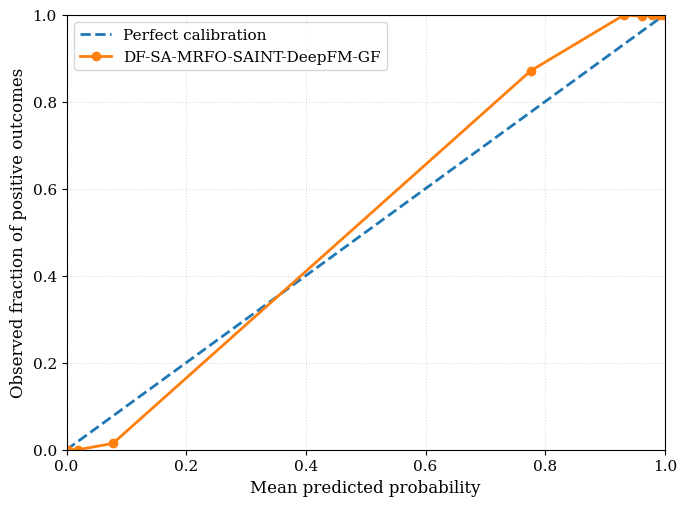

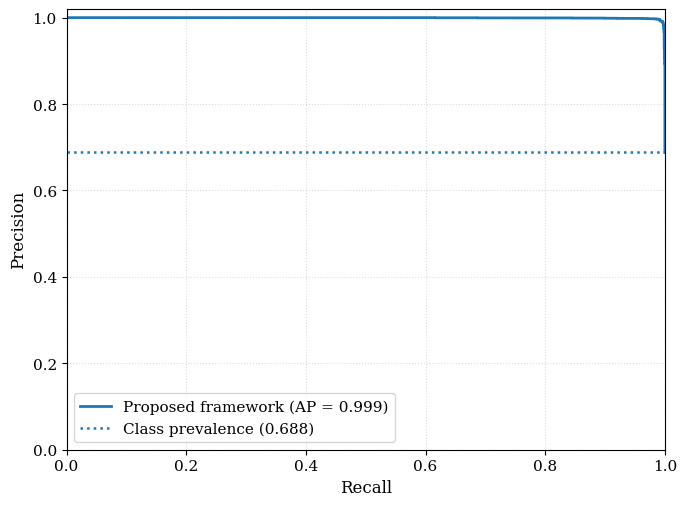

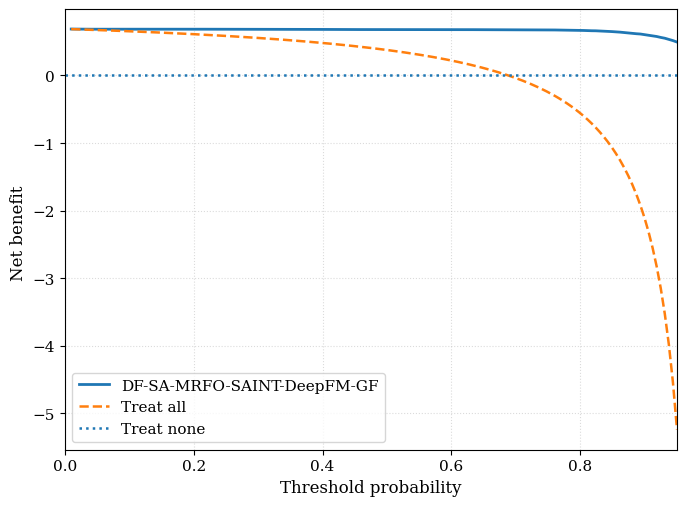

In [ ]:
# Brier score / AUROC / AP + calibration, precision-recall, decision curve
from sklearn.metrics import brier_score_loss, average_precision_score, precision_recall_curve
PROP = "Proposed DF-SA-MRFO-SAINT-DeepFM-GF"
MODEL_LABEL = "DF-SA-MRFO-SAINT-DeepFM-GF"

prob_prop = predict_proba(final_model, Xc_te, Xk_te, BEST_HP["batch_size"]).astype(np.float64)
if PROP in BASE_PRED and not np.array_equal((prob_prop >= TAU).astype(int), BASE_PRED[PROP]):
    print("WARNING: thresholded probabilities differ from BASE_PRED[PROP]; was final_model retrained after BASE_PRED was created?")
y = y_true.astype(int); N = len(y); prevalence = y.mean()

#  point estimates + 95% stratified bootstrap CIs
METRIC_FNS = {"Brier score": brier_score_loss, "AUROC": roc_auc_score, "Average precision": average_precision_score}
def stratified_bootstrap_prob(y, p, fns, n_boot=N_BOOT_BASE, level=CI_LVL, seed=SEED):
    rng = np.random.default_rng(seed); pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    draws = {k: [] for k in fns}
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        for k, f in fns.items(): draws[k].append(f(y[idx], p[idx]))
    lo, hi = (1 - level) / 2 * 100, (1 + level) / 2 * 100
    return {k: (float(np.percentile(v, lo)), float(np.percentile(v, hi))) for k, v in draws.items()}
CI_P = stratified_bootstrap_prob(y, prob_prop, METRIC_FNS)
prob_rows = []
for k, f in METRIC_FNS.items():
    prob_rows.append({"Metric": k, "Value": round(float(f(y, prob_prop)), 4), "95% CI": f"{CI_P[k][0]:.4f}-{CI_P[k][1]:.4f}"})
prob_table = pd.DataFrame(prob_rows); print(prob_table.to_string(index=False))
prob_table.to_csv(os.path.join(OUT_DIR, "probabilistic_metrics.csv"), index=False)

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.grid": True,
    "grid.linestyle": ":",
    "grid.alpha": 0.5,
    "axes.linewidth": 1.0,
    "legend.frameon": True,
})
FIGSIZE = (7, 5.2)

# calibration curve
edges = np.linspace(0, 1, 11); b_idx = np.searchsorted(edges[1:-1], prob_prop)
cal = [(prob_prop[b_idx == b].mean(), y[b_idx == b].mean(), int((b_idx == b).sum())) for b in range(10) if (b_idx == b).any()]
mean_pred, frac_pos, bin_n = map(np.array, zip(*cal))
print("\nCalibration bins: mean predicted | observed fraction | n")
for mp, fp_, n in zip(mean_pred, frac_pos, bin_n): print(f"  {mp:.3f}  {fp_:.3f}  {n}")

plt.figure(figsize=FIGSIZE)
plt.plot([0, 1], [0, 1], "--", color="tab:blue", lw=2, label="Perfect calibration")
plt.plot(mean_pred, frac_pos, "o-", color="tab:orange", lw=2, label=MODEL_LABEL)
plt.xlabel("Mean predicted probability"); plt.ylabel("Observed fraction of positive outcomes")
plt.xlim(0, 1); plt.ylim(0, 1); plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

#  precision-recall curve
prec, rec, _ = precision_recall_curve(y, prob_prop); ap = average_precision_score(y, prob_prop)
plt.figure(figsize=FIGSIZE)
plt.plot(rec, prec, color="tab:blue", lw=2, label=f"Proposed framework (AP = {ap:.3f})")
plt.axhline(prevalence, ls=":", color="tab:blue", lw=2, label=f"Class prevalence ({prevalence:.3f})")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.xlim(0, 1); plt.ylim(0, 1.02); plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

#  decision-curve analysis
def net_benefit(pt):
    pred = prob_prop >= pt; tp = int((pred & (y == 1)).sum()); fp = int((pred & (y == 0)).sum())
    return tp / N - fp / N * pt / (1 - pt)
thr = np.round(np.linspace(0.01, 0.95, 95), 2)
nb_model = np.array([net_benefit(t) for t in thr])
nb_all = prevalence - (1 - prevalence) * thr / (1 - thr)
nb_none = np.zeros_like(thr)

plt.figure(figsize=FIGSIZE)
plt.plot(thr, nb_model, color="tab:blue", lw=2, label=MODEL_LABEL)
plt.plot(thr, nb_all, color="tab:orange", lw=2, ls="--", label="Treat all")
plt.plot(thr, nb_none, color="tab:blue", lw=2, ls=":", label="Treat none")
plt.xlabel("Threshold probability"); plt.ylabel("Net benefit")
plt.xlim(0, 0.95); plt.legend(loc="lower left")
plt.tight_layout()
plt.show()
